# Quality Control For Mol-JEPA Embeddings

We have provided embeddings from the [Mol-JEPA](https://arxiv.org/pdf/2608.22642) foundation model for a subset of the drugs in the Harmonized Drug Dataset (HDD) ([version 3.1](https://www.orcestra.ca/annotations/6ae4fc5833e1ba54a5335fda)).  
Briefly, Mol-JEPA is a **J**oint **E**mbedding and **P**rediction **A**rchitecture which is trained to harmonize the latent spaces of existing drug foundation models with existing drug features. For details on how Mol-JEPA was trained, please refer to the [preprint](https://arxiv.org/pdf/2608.22642). 


At present the embeddings we have provided are the `<CLS>` (classification) tokens provided from the inference step of the Mol-JEPA model (see the [Huggingface Model Card](https://huggingface.co/Flogrammer/Mol-JEPA)). 

This notebook presumes you've run ``download.py``, ```construct_drug_universe.py```, and ```generate_embeddings.py``` in that order. 






## Environment Set Up

We load in the environment, the embeddings we computed, and define a utility function for handling [ATC code levels](https://www.who.int/tools/atc-ddd-toolkit/atc-classification). 

In [53]:
import matplotlib.pyplot as plt
import seaborn as sns
import umap
import pandas as pd
from damply import dirs
import os 
from pathlib import Path
from sklearn.preprocessing import StandardScaler
import re
import umap
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import LabelEncoder
from collections import defaultdict


def process_atc_code(code_string: str, level: int = 4) -> str:
    """Return the requested ATC hierarchy level (for example N03AX09 -> N03A)."""
    result = re.findall(r"[a-zA-Z]|[^a-zA-Z]+", code_string)
    return "".join(result[:level])


In [54]:
data = pd.read_csv(dirs.RESULTS / "molecule_embeddings.csv",index_col=0)

embedding_columns = data.columns[2:]

# Predicting Liver Hepatotoxicity Likelihood Score

A common problem with the administration of therapeutics is their toxicity. A drug that is effective in treating a given disease may need to be stopped prematurely if it is fatally damaging organs such as the liver or kidney.  We have curated liver toxicity information from Liver Toxicity Knowledgebase which provides liver toxicity grade scores ranging from 0 to 8, with 8 being severe liver toxicity. 

We first need to read in the label data and drop the compounds without a PubChem ID and without a label. 

In [55]:
labels = pd.read_csv(dirs.RAWDATA / "HDD/colData.tsv",
                      sep="\t",
                      usecols =  ["HDD.Compound.ID", "Pubchem.CID", "LTKB.DILI.Severity.Grade"])


labels = labels.dropna(subset= ["Pubchem.CID", "LTKB.DILI.Severity.Grade"])


Next let's look at how many of each class there are.

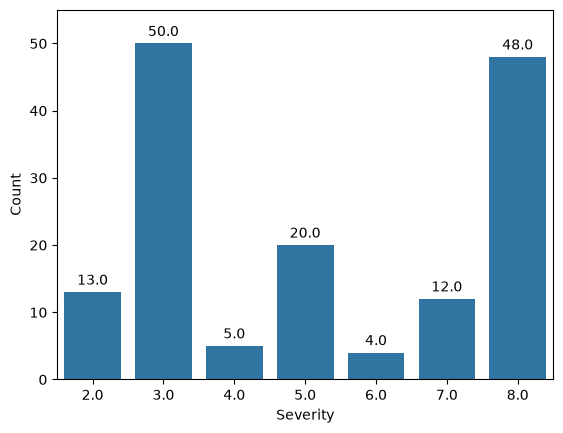

In [56]:
class_counts = pd.DataFrame(labels["LTKB.DILI.Severity.Grade"].value_counts()).reset_index()
class_counts.columns = ['Severity', 'Count']
ax = sns.barplot(data=class_counts, x="Severity", y="Count", errorbar=None)
ax.bar_label(ax.containers[0], fmt="%.1f", padding=3)
ax.margins(y=0.1)
plt.show()

We see that the classes are rather imbalanced, with most of the drugs having either a middle range toxicity of 3 or a severe toxicity of 8. In order to build a more functional classifier we bin these as 'high' or 'low' depending on if the grade is greater than or equal to 4. 

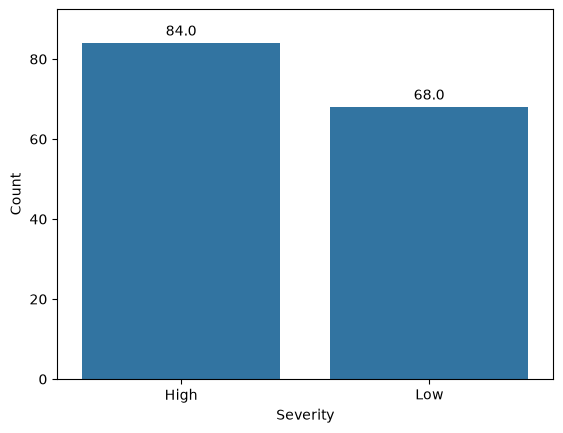

In [29]:
labels['Binned Tox'] = ['High' if x>4 else 'Low' for x in labels["LTKB.DILI.Severity.Grade"]]
class_counts = pd.DataFrame(labels["Binned Tox"].value_counts()).reset_index()
class_counts.columns = ['Severity', 'Count']
ax = sns.barplot(data=class_counts, x="Severity", y="Count", errorbar=None)
ax.bar_label(ax.containers[0], fmt="%.1f", padding=3)
ax.margins(y=0.1)
plt.show()

That's a lot closer to even! Let's try building a classifier on this data. In order to do this we need to make our data amenable for a classifier. 

In [31]:
classification_data = data.merge(labels, on='HDD.Compound.ID')
classification_data.shape

(152, 517)

We only have 150 samples with labels, which isn't a lot to build a classifier so our results may be subject to statistical noise. As the classes are not perfeclty balanced, we used a stratified split to ensure that the label distribution does not impact training. We try several classification models. 

In [40]:
X = classification_data[embedding_columns].to_numpy()
y = LabelEncoder().fit_transform(labels['Binned Tox'])
NUM_SPLITS = 20

models = {
            "RF": RandomForestClassifier(max_depth=2, random_state=0),
            "MLP": MLPClassifier(max_iter=1000),
            "KNN": KNeighborsClassifier(n_neighbors=10),
        }
skf = StratifiedKFold(n_splits=NUM_SPLITS)
results = []

In [44]:
for fold, (train_index, test_index) in enumerate(skf.split(X, y), start=1):
    for model_name, clf in models.items():
                clf.fit(X[train_index], y[train_index])
                preds = clf.predict(X[test_index])
                results.append(
                    {
                        "Model": model_name,
                        "Fold": fold,
                        "Bal. Acc": balanced_accuracy_score(
                            y[test_index], preds
                        ),
                        "Acc": accuracy_score(y[test_index], preds),
                    }
                )
results = pd.DataFrame(
    results,
    columns=["Model", "Fold", "Bal. Acc", "Acc"],
)

Text(0.5, 1.0, 'Accuracy Across All Folds in Predicting Binnned Livertoxicity Grade')

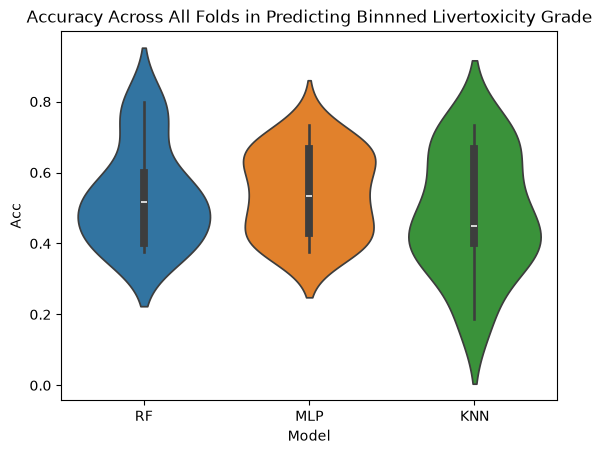

In [47]:
sns.violinplot(data=results, x="Model", y="Acc", hue="Model")
plt.title("Accuracy Across All Folds in Predicting Binnned Livertoxicity Grade")

We see that no model performs particularly well, which could be due to the small sample size and the large embeddings. 